
# Preparación y análisis del dataset Cassava

**Asignatura:** Inteligencia Artificial  
**Proyecto:** Clasificación de enfermedades foliares de yuca  
**Grupo:** 1

## Objetivo
Analizar las características, etiquetas, distribución e imágenes del dataset Cassava y preparar los datos para el entrenamiento de cuatro arquitecturas CNN: CNN propia, MobileNetV2, EfficientNetB0 y DenseNet121.

In [14]:
# PASO 1: Importación y verificación de librerías
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
import csv
from pathlib import Path
from tempfile import mkdtemp
from time import perf_counter

from tensorflow import keras
from tensorflow.keras import layers

# Mostrar versiones utilizadas
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
# Comprobar si existe una GPU disponible
print("GPU disponible:", tf.config.list_physical_devices("GPU"))
print("\nLibrerías importadas correctamente.")

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU disponible: []

Librerías importadas correctamente.


In [15]:
# Instalar la dependencia faltante
%pip install -q importlib_resources

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
# PASO 2: Carga del dataset Cassava
# Descargar el dataset y cargar sus tres particiones originales
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava",
    split=["train", "validation", "test"],
    with_info=True,
    as_supervised=False,
    shuffle_files=False
)
# Confirmar que el dataset fue cargado correctamente
print("Cassava descargado y particiones cargadas correctamente.")

Cassava descargado y particiones cargadas correctamente.


In [17]:
# PASO 3: Análisis de metadatos del dataset Cassava
# Mostrar información general del dataset
print("Nombre del dataset:", info.name)
print("Versión:", info.version)

# Mostrar la cantidad de imágenes por conjunto
print("\n--- DISTRIBUCIÓN DE DATOS ---")
total = 0

for nombre, datos in info.splits.items():
    print(f"{nombre}: {datos.num_examples} imágenes")
    total += datos.num_examples

print("Total de imágenes:", total)

# Mostrar la cantidad de clases y sus etiquetas
print("\n--- CLASES Y ETIQUETAS ---")
clases = info.features["label"].names

print("Número de clases:", len(clases))

for codigo, nombre in enumerate(clases):
    print(f"Etiqueta {codigo}: {nombre}")

# Mostrar las características de las imágenes
print("\n--- CARACTERÍSTICAS DE LAS IMÁGENES ---")
print("Dimensiones:", info.features["image"].shape)
print("Tipo de dato:", info.features["image"].np_dtype)
print("Características disponibles:", list(info.features.keys()))

Nombre del dataset: cassava
Versión: 0.1.0

--- DISTRIBUCIÓN DE DATOS ---
train: 5656 imágenes
test: 1885 imágenes
validation: 1889 imágenes
Total de imágenes: 9430

--- CLASES Y ETIQUETAS ---
Número de clases: 5
Etiqueta 0: cbb
Etiqueta 1: cbsd
Etiqueta 2: cgm
Etiqueta 3: cmd
Etiqueta 4: healthy

--- CARACTERÍSTICAS DE LAS IMÁGENES ---
Dimensiones: (None, None, 3)
Tipo de dato: <class 'numpy.uint8'>
Características disponibles: ['image', 'image/filename', 'label']


In [18]:
# PASO 3.1: Análisis de clases y dimensiones de las imágenes
from collections import Counter
# Contadores de etiquetas y dimensiones
conteo_clases = Counter()
conteo_tamanos = Counter()

# Recorrer las imágenes originales de los tres conjuntos
for dataset in (ds_train, ds_val, ds_test):
    for registro in tfds.as_numpy(dataset):
        conteo_clases[int(registro["label"])] += 1

        alto, ancho = registro["image"].shape[:2]
        conteo_tamanos[(ancho, alto)] += 1

# Mostrar cantidad de imágenes por clase
print("--- IMÁGENES POR CLASE ---")
for i, clase in enumerate(clases):
    print(f"Etiqueta {i} ({clase}): {conteo_clases[i]} imágenes")

print("Total:", sum(conteo_clases.values()))

# Identificar las dimensiones mínima, máxima y más frecuente
menor = min(conteo_tamanos, key=lambda x: x[0] * x[1])
mayor = max(conteo_tamanos, key=lambda x: x[0] * x[1])
frecuente, cantidad = conteo_tamanos.most_common(1)[0]

# Mostrar resultados de las dimensiones
print("\n--- DIMENSIONES DE LAS IMÁGENES ---")
print("Tamaño más pequeño:", menor)
print("Tamaño más grande:", mayor)
print("Tamaño más frecuente:", frecuente)
print("Imágenes con ese tamaño mas frecuentes:", cantidad)
print("Tamaños diferentes encontrados:", len(conteo_tamanos))

--- IMÁGENES POR CLASE ---
Etiqueta 0 (cbb): 777 imágenes
Etiqueta 1 (cbsd): 2406 imágenes
Etiqueta 2 (cgm): 1289 imágenes
Etiqueta 3 (cmd): 4431 imágenes
Etiqueta 4 (healthy): 527 imágenes
Total: 9430

--- DIMENSIONES DE LAS IMÁGENES ---
Tamaño más pequeño: (420, 500)
Tamaño más grande: (1622, 500)
Tamaño más frecuente: (500, 666)
Imágenes con ese tamaño mas frecuentes: 2369
Tamaños diferentes encontrados: 669


In [19]:
# PASO 3.2: Distribución de clases en Train, Validation y Test
# Crear los conjuntos que vamos a analizar
particiones = {
    "Train": ds_train,
    "Validation": ds_val,
    "Test": ds_test
}

# Contar las etiquetas de cada conjunto
conteos = {}

for nombre, dataset in particiones.items():
    etiquetas = [
        int(x) for x in tfds.as_numpy(
            dataset.map(lambda registro: registro["label"])
        )
    ]
    conteos[nombre] = np.bincount(etiquetas, minlength=len(clases))

# Mostrar una tabla comparativa
print(f"{'Clase':<10} {'Train':>8} {'Validation':>12} {'Test':>8}")

for i, clase in enumerate(clases):
    print(f"{clase:<10} {conteos['Train'][i]:>8} "
          f"{conteos['Validation'][i]:>12} {conteos['Test'][i]:>8}")

# Comprobar los totales de cada partición
print("\nTotales:")
for nombre, cantidades in conteos.items():
    print(f"{nombre}: {cantidades.sum()} imágenes")

Clase         Train   Validation     Test
cbb             466          156      155
cbsd           1443          482      481
cgm             773          258      258
cmd            2658          887      886
healthy         316          106      105

Totales:
Train: 5656 imágenes
Validation: 1889 imágenes
Test: 1885 imágenes


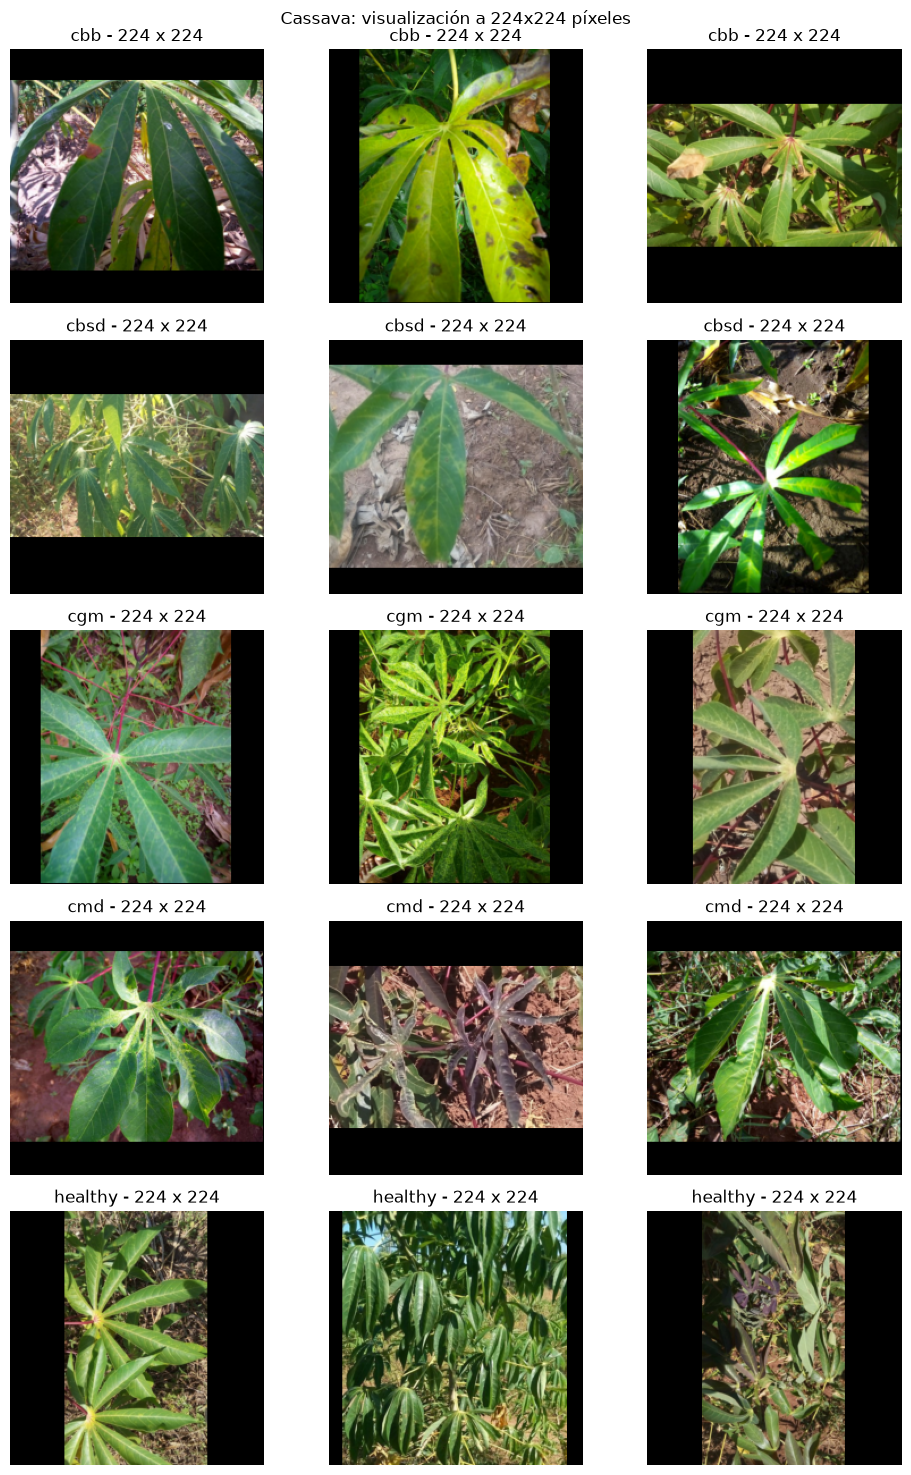

In [20]:
# PASO 4: Visualización de imágenes redimensionadas a 224x224
# Seleccionar 3 imágenes de cada clase del conjunto Train
muestras = {i: [] for i in range(len(clases))}

for registro in tfds.as_numpy(ds_train):
    etiqueta = int(registro["label"])

    if len(muestras[etiqueta]) < 3:
        muestras[etiqueta].append(registro["image"])

    # Detener cuando tengamos las 15 imágenes
    if all(len(lista) == 3 for lista in muestras.values()):
        break

# Mostrar las 15 imágenes con resolución de 224x224
fig, ejes = plt.subplots(5, 3, figsize=(10, 15))

for i, clase in enumerate(clases):
    for j, imagen in enumerate(muestras[i]):
        # Redimensionar conservando la proporción original
        imagen_224 = tf.image.resize_with_pad(
            imagen, 224, 224, antialias=True
        )
        # Visualizar la imagen con su etiqueta
        ejes[i, j].imshow(tf.cast(imagen_224, tf.uint8))
        ejes[i, j].set_title(f"{clase} - 224 x 224")
        ejes[i, j].axis("off")

plt.suptitle("Cassava: visualización a 224x224 píxeles")
plt.tight_layout()
plt.show()

In [21]:
# PASO 5: Preparación de datos para el entrenamiento
# Definir parámetros generales
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Función para redimensionar cada imagen y conservar su etiqueta
def preparar_imagen(registro):
    imagen = tf.image.resize_with_pad(
        registro["image"],
        IMG_SIZE[0],
        IMG_SIZE[1],
        antialias=True,)
    # Mantener los píxeles float32 en el rango común de 0 a 255.
    imagen = tf.clip_by_value(imagen, 0.0, 255.0)
    return imagen, registro["label"]
# Función para organizar los datos en lotes
def preparar_dataset(dataset, entrenamiento=False):

    # Mezclar únicamente las imágenes de entrenamiento
    if entrenamiento:
        dataset = dataset.shuffle(1000, seed=42)
    # Redimensionar las imágenes
    dataset = dataset.map(
        preparar_imagen, num_parallel_calls=AUTOTUNE
    )
    # Agrupar las imágenes y optimizar su lectura
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset
# Preparar Train, Validation y Test
train_preparado = preparar_dataset(ds_train, entrenamiento=True)
val_preparado = preparar_dataset(ds_val)
test_preparado = preparar_dataset(ds_test)

print("Datos preparados correctamente.")

# Comprobar las dimensiones de un lote
for imagenes, etiquetas in train_preparado.take(1):
    print("Dimensiones del lote:", imagenes.shape)
    print("Dimensiones de etiquetas:", etiquetas.shape)
    print("Tipo de dato:", imagenes.dtype)

Datos preparados correctamente.
Dimensiones del lote: (32, 224, 224, 3)
Dimensiones de etiquetas: (32,)
Tipo de dato: <dtype: 'float32'>


Clase        Fotos    Mediana        P90    Más de 50%
cbb            466      20.0%      24.9%          0.2%
cbsd          1443      24.9%      43.7%          0.0%
cgm            773      24.9%      43.7%          0.8%
cmd           2658      24.9%      43.7%          0.5%
healthy        316      20.0%      43.7%          0.6%


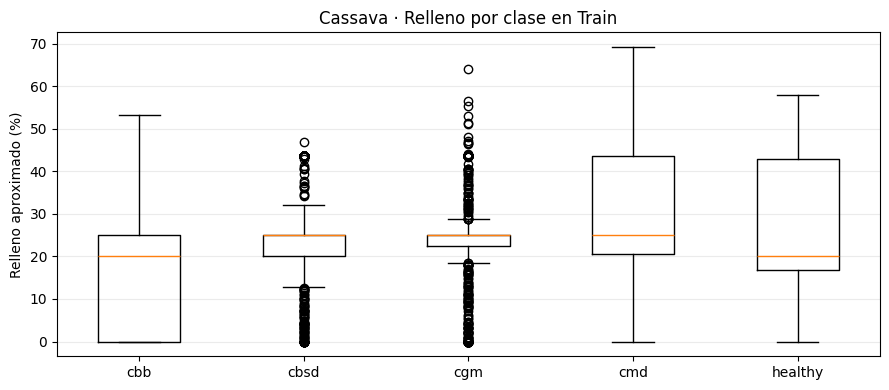

In [9]:
# PASO 6: Medir cuánto relleno necesita cada clase de Cassava
from collections import defaultdict

relleno_por_clase = defaultdict(list)

# Buscamos fotos casi cuadradas, moderadamente rectangulares y alargadas.
# El valor representa lado corto / lado largo.
proporciones_objetivo = [1.00, 0.75, 0.40]
muestras_comparacion = {}

for registro in tfds.as_numpy(ds_train):
    imagen = registro["image"]
    etiqueta = int(registro["label"])
    alto, ancho = imagen.shape[:2]

    proporcion = min(alto, ancho) / max(alto, ancho)
    porcentaje_relleno = 100 * (1 - proporcion)
    relleno_por_clase[etiqueta].append(porcentaje_relleno)

    # Guardar, para cada clase, la foto más cercana a cada proporción.
    for objetivo in proporciones_objetivo:
        clave = (etiqueta, objetivo)
        distancia = abs(proporcion - objetivo)
        anterior = muestras_comparacion.get(clave)

        if anterior is None or distancia < anterior["distancia"]:
            muestras_comparacion[clave] = {
                "distancia": distancia,
                "imagen": imagen,
                "relleno": porcentaje_relleno,
            }

print(f"{'Clase':<10} {'Fotos':>7} {'Mediana':>10} {'P90':>10} {'Más de 50%':>13}")

for etiqueta, nombre in enumerate(clases):
    valores = np.array(relleno_por_clase[etiqueta])

    print(
        f"{nombre:<10} {len(valores):>7} "
        f"{np.median(valores):>9.1f}% "
        f"{np.percentile(valores, 90):>9.1f}% "
        f"{np.mean(valores > 50) * 100:>12.1f}%"
    )

plt.figure(figsize=(9, 4))
plt.boxplot([relleno_por_clase[i] for i in range(len(clases))])
plt.xticks(range(1, len(clases) + 1), clases)
plt.ylabel("Relleno aproximado (%)")
plt.title("Cassava · Relleno por clase en Train")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

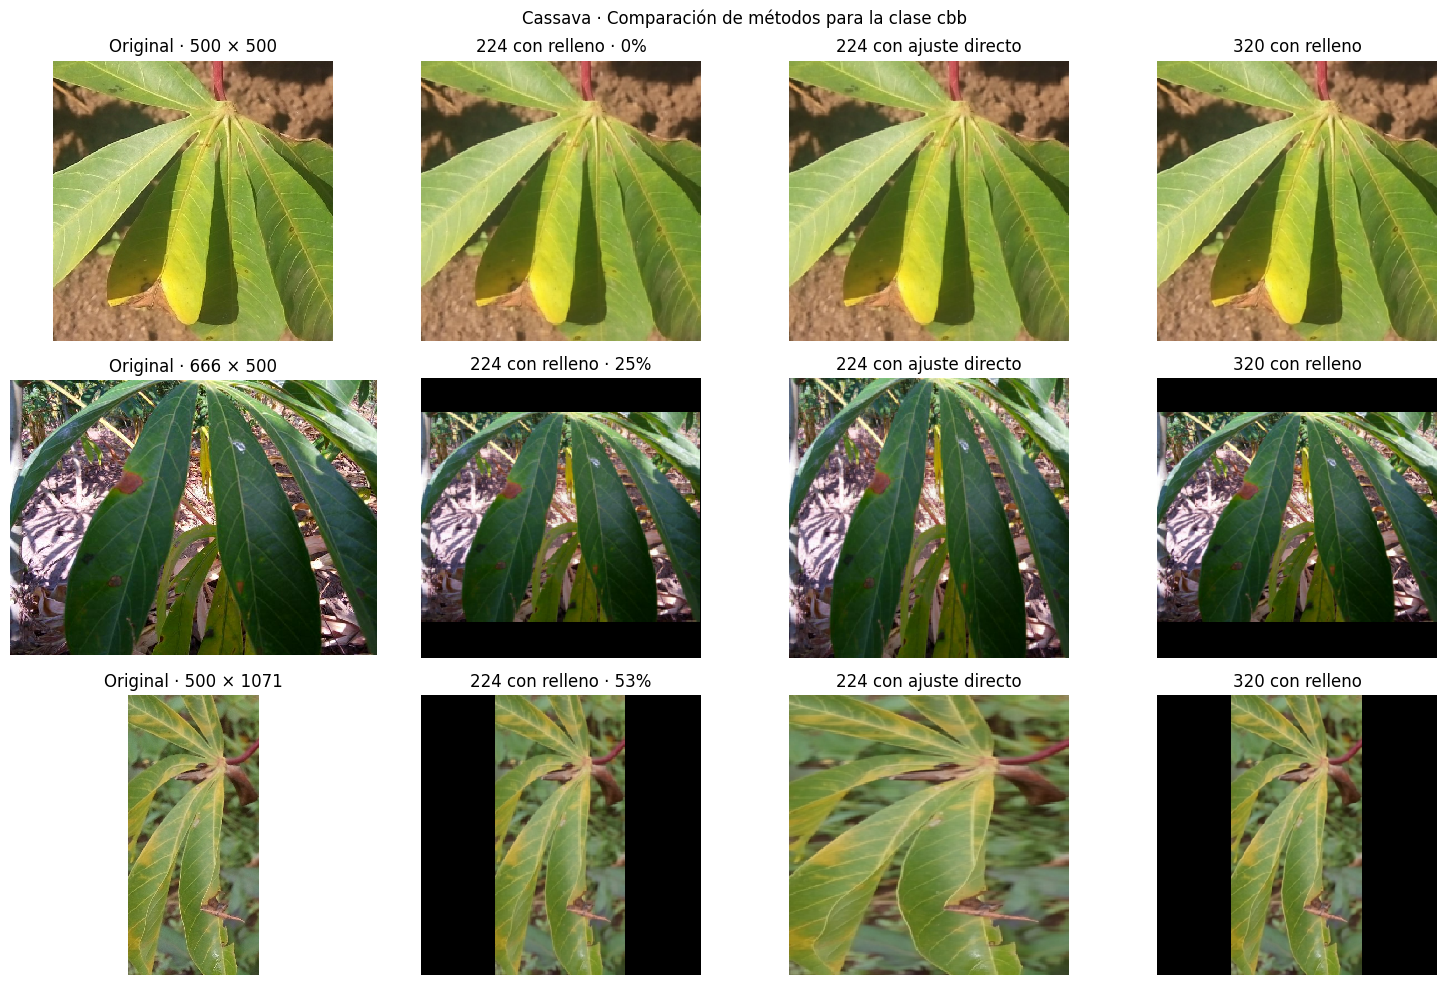

In [10]:
# PASO 7: Comparar el redimensionamiento sobre las mismas fotos
clase_a_revisar = "cbb"
etiqueta = list(clases).index(clase_a_revisar)

fig, ejes = plt.subplots(3, 4, figsize=(15, 10))

for fila, objetivo in enumerate(proporciones_objetivo):
    muestra = muestras_comparacion[(etiqueta, objetivo)]
    original = muestra["imagen"]
    alto, ancho = original.shape[:2]

    con_relleno_224 = tf.image.resize_with_pad(
        original, 224, 224, antialias=True
    )
    directo_224 = tf.image.resize(
        original, (224, 224), antialias=True
    )
    con_relleno_320 = tf.image.resize_with_pad(
        original, 320, 320, antialias=True
    )

    versiones = [
        (original, f"Original · {ancho} × {alto}"),
        (con_relleno_224, f"224 con relleno · {muestra['relleno']:.0f}%"),
        (directo_224, "224 con ajuste directo"),
        (con_relleno_320, "320 con relleno"),
    ]

    for eje, (imagen, titulo) in zip(ejes[fila], versiones):
        # Conversión solo para que Matplotlib muestre bien los colores.
        imagen_visible = np.clip(np.asarray(imagen), 0, 255).astype(np.uint8)
        eje.imshow(imagen_visible, interpolation="nearest")
        eje.set_title(titulo)
        eje.axis("off")

fig.suptitle(f"Cassava · Comparación de métodos para la clase {clase_a_revisar}")
plt.tight_layout()
plt.show()

In [11]:
print(f"Máximo real del lote: {tf.reduce_max(imagenes).numpy():.8f}")

Máximo real del lote: 255.00000000


In [12]:
# PASO 8: Verificar las entradas antes de entrenar la CNN propia
for nombre, dataset in [
    ("Train", train_preparado),
    ("Validation", val_preparado),
]:
    imagenes, etiquetas = next(iter(dataset))

    tf.debugging.assert_shapes([
        (imagenes, ("lote", 224, 224, 3)),
        (etiquetas, ("lote",)),
    ])
    tf.debugging.assert_all_finite(imagenes, f"{nombre}: píxeles no finitos")
    tf.debugging.assert_greater_equal(imagenes, 0.0)
    tf.debugging.assert_less_equal(imagenes, 255.0)
    tf.debugging.assert_greater_equal(etiquetas, tf.cast(0, etiquetas.dtype))
    tf.debugging.assert_less(
        etiquetas, tf.cast(len(clases), etiquetas.dtype)
    )

    print(
        f"{nombre} | imágenes: {imagenes.shape} | "
        f"etiquetas: {etiquetas.shape} | "
        f"píxeles: {float(tf.reduce_min(imagenes)):.1f} a "
        f"{float(tf.reduce_max(imagenes)):.1f}"
    )
print("Los lotes de Train y Validation pasaron la verificación.")

Train | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Validation | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Los lotes de Train y Validation pasaron la verificación.


In [13]:
# PASO 9: Construir la CNN propia para Cassava
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

cnn_cassava = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.25),
    layers.Dense(len(clases), activation="softmax"),
], name="cnn_propia_cassava")

cnn_cassava.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

cnn_cassava.summary()

Model: "cnn_propia_cassava"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,893 (366.77 KB)

 Trainable params: 93,893 (366.77 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# PASO 10: Comprobar que la CNN entrena y valida con los datos preparados
historial_piloto = cnn_cassava.fit(
    train_preparado.take(8),
    validation_data=val_preparado.take(4),
    epochs=1,
    callbacks=[keras.callbacks.TerminateOnNaN()],
    verbose=1,
)

print("\nResultados de la prueba corta")
for metrica, valores in historial_piloto.history.items():
    print(f"{metrica}: {valores[-1]:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 0.4570 - loss: 1.4852 - val_accuracy: 0.4219 - val_loss: 1.5221

Resultados de la prueba corta
accuracy: 0.4570
loss: 1.4852
val_accuracy: 0.4219
val_loss: 1.5221


In [15]:
# PASO 11: Primera corrida formal de la CNN propia en Cassava
from pathlib import Path
from datetime import datetime
from time import perf_counter

fecha = datetime.now().strftime("%Y%m%d_%H%M%S")
carpeta_corrida = Path(f"resultados/cnn_cassava_224_relleno_lr001_{fecha}")
carpeta_corrida.mkdir(parents=True, exist_ok=True)

ruta_modelo = carpeta_corrida / "mejor_modelo.keras"

controles = [
    keras.callbacks.CSVLogger(str(carpeta_corrida / "historial.csv")),
    keras.callbacks.ModelCheckpoint(
        filepath=str(ruta_modelo),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        restore_best_weights=True,
    ),
    keras.callbacks.TerminateOnNaN(),
]

print("GPU detectada:", tf.config.list_physical_devices("GPU"))
inicio = perf_counter()

historial_cnn_01 = cnn_cassava.fit(
    train_preparado,
    validation_data=val_preparado,
    epochs=10,
    callbacks=controles,
    verbose=1,
)

duracion = perf_counter() - inicio
mejor_indice = int(np.argmin(historial_cnn_01.history["val_loss"]))

print(f"\nTiempo de entrenamiento: {duracion / 60:.2f} minutos")
print(f"Mejor época según val_loss: {mejor_indice + 1}")
for metrica, valores in historial_cnn_01.history.items():
    print(f"{metrica}: {valores[mejor_indice]:.4f}")

print(f"Archivos guardados en: {carpeta_corrida}")

GPU detectada: []
Epoch 1/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 757s 4s/step - accuracy: 0.4698 - loss: 1.3309 - val_accuracy: 0.4696 - val_loss: 1.3040
Epoch 2/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 727s 4s/step - accuracy: 0.5081 - loss: 1.2667 - val_accuracy: 0.5352 - val_loss: 1.2091
Epoch 3/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 744s 4s/step - accuracy: 0.5736 - loss: 1.1722 - val_accuracy: 0.5744 - val_loss: 1.1346
Epoch 4/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 744s 4s/step - accuracy: 0.5898 - loss: 1.1318 - val_accuracy: 0.6289 - val_loss: 1.0869
Epoch 5/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 714s 4s/step - accuracy: 0.6008 - loss: 1.1060 - val_accuracy: 0.6416 - val_loss: 1.0420
Epoch 6/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 730s 4s/step - accuracy: 0.6128 - loss: 1.0768 - val_accuracy: 0.6411 - val_loss: 1.0211
Epoch 7/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 755s 4s/step - accuracy: 0.6178 - loss: 1.0725 - val_accuracy: 0.6453 - val_loss: 1.0285
Epoch 8/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 733s 4s/step - accuracy: 0.6238 - loss:

Total de fotos: 1889
Aciertos: 1232
Errores: 657
Exactitud: 65.22%

Resultados por clase
              precision    recall  f1-score   support

         cbb       0.70      0.31      0.43       156
        cbsd       0.67      0.68      0.67       482
         cgm       0.00      0.00      0.00       258
         cmd       0.64      0.97      0.77       887
     healthy       0.00      0.00      0.00       106

    accuracy                           0.65      1889
   macro avg       0.40      0.39      0.38      1889
weighted avg       0.53      0.65      0.57      1889



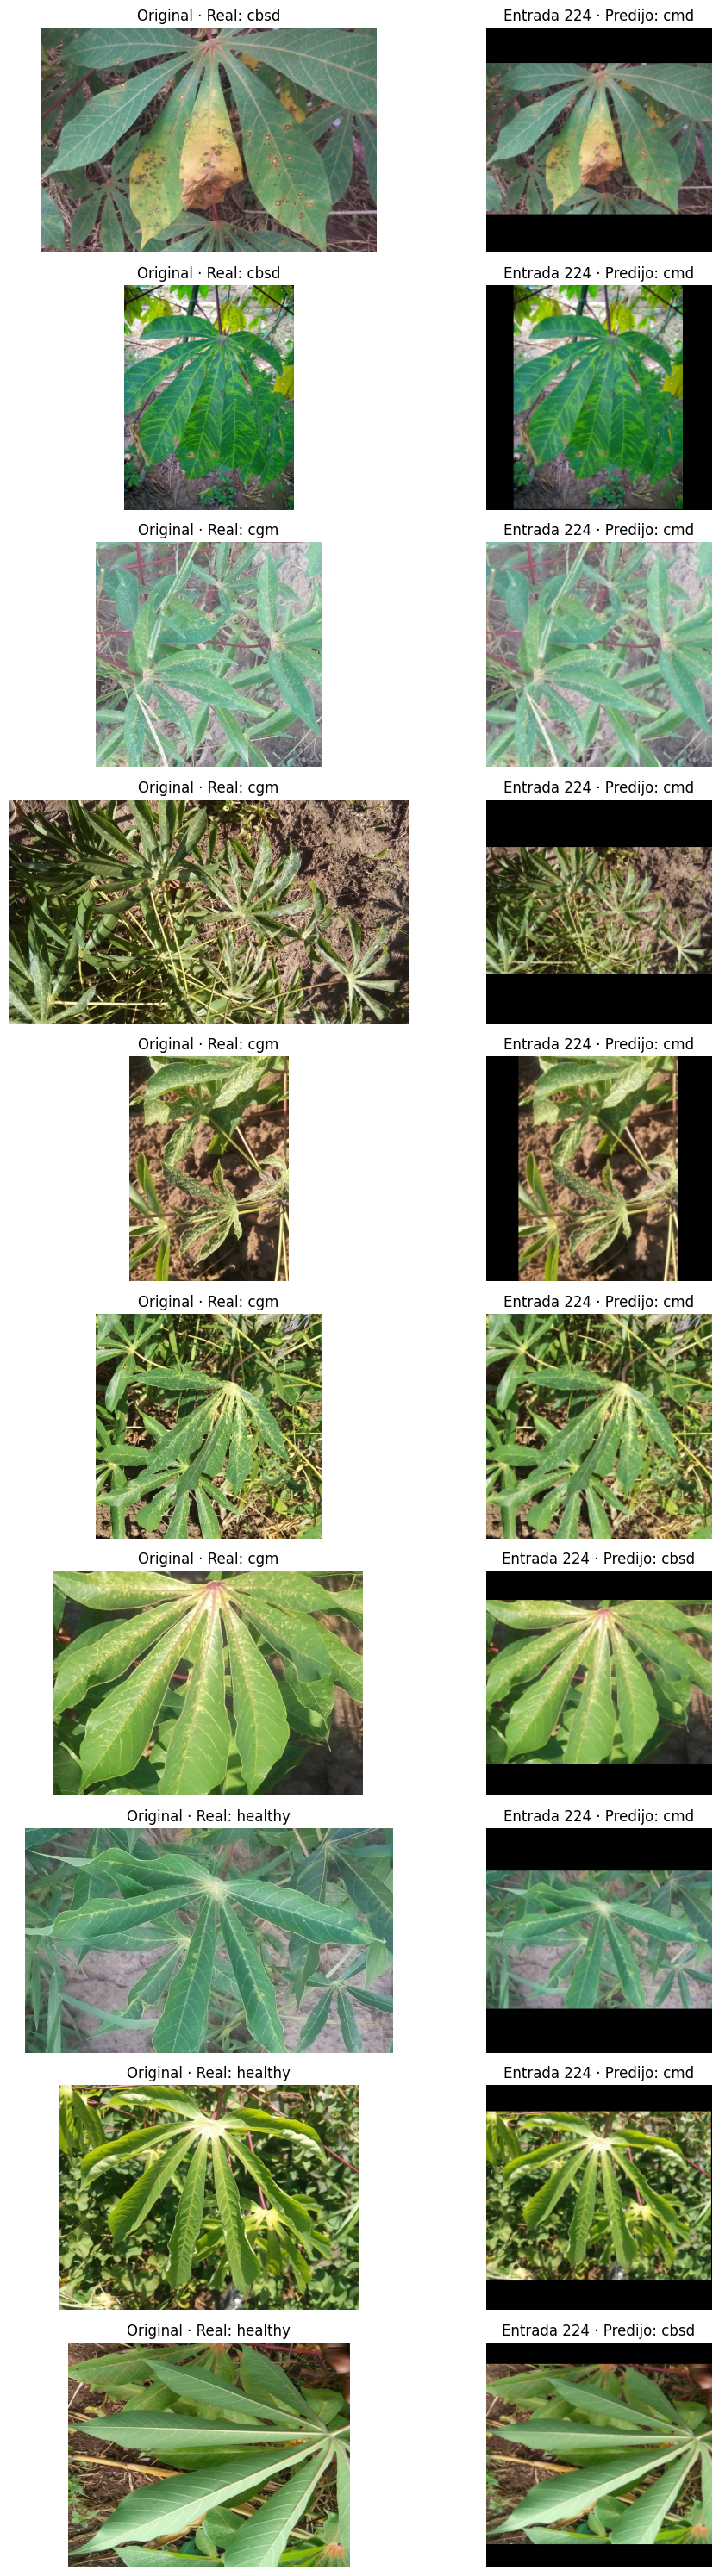

In [16]:
# PASO 12: Contar y revisar errores de la CNN en Validation
from sklearn.metrics import classification_report

mejor_cnn = keras.models.load_model(str(ruta_modelo), compile=False)

reales = []
predichas = []

# Cada predicción se recoge junto con las etiquetas del mismo lote.
for imagenes, etiquetas in val_preparado:
    probabilidades = mejor_cnn(imagenes, training=False).numpy()
    reales.extend(etiquetas.numpy())
    predichas.extend(np.argmax(probabilidades, axis=1))

reales = np.asarray(reales)
predichas = np.asarray(predichas)
indices_error = np.flatnonzero(reales != predichas)

print(f"Total de fotos: {len(reales)}")
print(f"Aciertos: {len(reales) - len(indices_error)}")
print(f"Errores: {len(indices_error)}")
print(f"Exactitud: {100 * np.mean(reales == predichas):.2f}%")

print("\nResultados por clase")
print(classification_report(
    reales,
    predichas,
    labels=list(range(len(clases))),
    target_names=list(clases),
    zero_division=0,
))

if len(indices_error) > 0:
    # Elegir una muestra reproducible entre todas las fotos mal clasificadas.
    rng = np.random.default_rng(42)
    seleccion = set(rng.choice(
        indices_error,
        size=min(10, len(indices_error)),
        replace=False,
    ).tolist())

    fig, ejes = plt.subplots(
        len(seleccion), 2, figsize=(10, 3 * len(seleccion)),
        squeeze=False,
    )

    # El Paso 5 conserva el orden de ds_val en val_preparado.
    fila = 0
    for indice, registro in enumerate(ds_val):
        if indice not in seleccion:
            continue

        original = registro["image"].numpy()
        imagen_224, etiqueta = preparar_imagen(registro)
        assert int(etiqueta.numpy()) == reales[indice]

        ejes[fila, 0].imshow(original)
        ejes[fila, 0].set_title(f"Original · Real: {clases[reales[indice]]}")

        ejes[fila, 1].imshow(imagen_224.numpy() / 255.0)
        ejes[fila, 1].set_title(f"Entrada 224 · Predijo: {clases[predichas[indice]]}")

        for eje in ejes[fila]:
            eje.axis("off")

        fila += 1
        if fila == len(seleccion):
            break

    plt.tight_layout()
    plt.show()

In [17]:
# PASO 13: Segunda corrida de la CNN propia con pesos por clase
from pathlib import Path
from tempfile import mkdtemp
from time import perf_counter

# Usar únicamente los conteos de Train, en el orden oficial de clases.
conteos_train = np.asarray(conteos["Train"], dtype=float)

# Suavizar la ponderación con raíz cuadrada y dejar el peso medio en 1.
pesos = 1.0 / np.sqrt(conteos_train)
pesos /= np.average(pesos, weights=conteos_train)
pesos_clase = {i: float(peso) for i, peso in enumerate(pesos)}

for i, nombre in enumerate(clases):
    print(f"{nombre}: {int(conteos_train[i])} fotos · peso {pesos_clase[i]:.2f}")

keras.utils.set_random_seed(42)
cnn_ponderada = keras.models.clone_model(cnn_cassava)
cnn_ponderada.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

# Reconstruir Train con el mismo procedimiento de preparación del Paso 5.
train_corrida_02 = preparar_dataset(ds_train, entrenamiento=True)

Path("resultados").mkdir(exist_ok=True)
carpeta_02 = Path(mkdtemp(prefix="cnn_cassava_ponderada_", dir="resultados"))
ruta_modelo_02 = carpeta_02 / "mejor_modelo.keras"

inicio = perf_counter()
historial_cnn_02 = cnn_ponderada.fit(
    train_corrida_02,
    validation_data=val_preparado,
    class_weight=pesos_clase,
    epochs=10,
    callbacks=[
        keras.callbacks.CSVLogger(str(carpeta_02 / "historial.csv")),
        keras.callbacks.ModelCheckpoint(
            str(ruta_modelo_02), monitor="val_loss",
            mode="min", save_best_only=True,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min", patience=3,
            restore_best_weights=True,
        ),
        keras.callbacks.TerminateOnNaN(),
    ],
    verbose=1,
)

print(f"\nTiempo: {(perf_counter() - inicio) / 60:.2f} minutos")
print(f"Modelo guardado en: {ruta_modelo_02}")

cbb: 466 fotos · peso 1.67
cbsd: 1443 fotos · peso 0.95
cgm: 773 fotos · peso 1.30
cmd: 2658 fotos · peso 0.70
healthy: 316 fotos · peso 2.03
Epoch 1/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 762s 4s/step - accuracy: 0.4707 - loss: 1.5203 - val_accuracy: 0.5368 - val_loss: 1.3723
Epoch 2/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 759s 4s/step - accuracy: 0.5414 - loss: 1.4086 - val_accuracy: 0.5453 - val_loss: 1.2889
Epoch 3/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 714s 4s/step - accuracy: 0.5744 - loss: 1.3460 - val_accuracy: 0.6284 - val_loss: 1.1314
Epoch 4/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 711s 4s/step - accuracy: 0.5889 - loss: 1.3074 - val_accuracy: 0.6220 - val_loss: 1.0972
Epoch 5/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 721s 4s/step - accuracy: 0.5907 - loss: 1.2897 - val_accuracy: 0.6167 - val_loss: 1.1243
Epoch 6/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 731s 4s/step - accuracy: 0.5955 - loss: 1.2703 - val_accuracy: 0.6395 - val_loss: 1.0573
Epoch 7/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 745s 4s/step - accuracy: 0.5941 - loss: 1.25

In [18]:
# PASO 14: Evaluar el modelo ponderado por clase
from sklearn.metrics import classification_report, confusion_matrix

modelo_02 = keras.models.load_model(str(ruta_modelo_02), compile=False)

def evaluar_por_clase(modelo, dataset):
    reales, predichas = [], []
    for imagenes, etiquetas in dataset:
        probabilidades = modelo(imagenes, training=False).numpy()
        reales.extend(etiquetas.numpy())
        predichas.extend(np.argmax(probabilidades, axis=1))
    return np.asarray(reales), np.asarray(predichas)

train_para_evaluar = preparar_dataset(ds_train)

for nombre, dataset in [
    ("Train", train_para_evaluar),
    ("Validation", val_preparado),
]:
    reales_02, predichas_02 = evaluar_por_clase(modelo_02, dataset)
    print(f"\n{nombre} · CNN con ponderación")
    print(classification_report(
        reales_02, predichas_02,
        labels=list(range(len(clases))),
        target_names=list(clases),
        digits=4,
        zero_division=0,
    ))

    if nombre == "Validation":
        print("Orden de clases:", list(clases))
        print(confusion_matrix(
            reales_02, predichas_02, labels=list(range(len(clases)))
        ))


Train · CNN con ponderación
              precision    recall  f1-score   support

         cbb     0.6361    0.4163    0.5032       466
        cbsd     0.7207    0.4900    0.5833      1443
         cgm     0.2697    0.0621    0.1009       773
         cmd     0.6173    0.9560    0.7502      2658
     healthy     0.5132    0.1234    0.1990       316

    accuracy                         0.6239      5656
   macro avg     0.5514    0.4096    0.4273      5656
weighted avg     0.5919    0.6239    0.5678      5656


Validation · CNN con ponderación
              precision    recall  f1-score   support

         cbb     0.6458    0.3974    0.4921       156
        cbsd     0.7389    0.5166    0.6081       482
         cgm     0.3000    0.0814    0.1280       258
         cmd     0.6251    0.9605    0.7573       887
     healthy     0.7826    0.1698    0.2791       106

    accuracy                         0.6363      1889
   macro avg     0.6185    0.4252    0.4529      1889
weighted avg  


CNN propia · Sin ponderación
Exactitud: 65.22%
F1 macro: 0.3758
cbb: 49/156 correctas · F1: 0.4336
cbsd: 327/482 correctas · F1: 0.6728
cgm: 0/258 correctas · F1: 0.0000
cmd: 856/887 correctas · F1: 0.7726
healthy: 0/106 correctas · F1: 0.0000


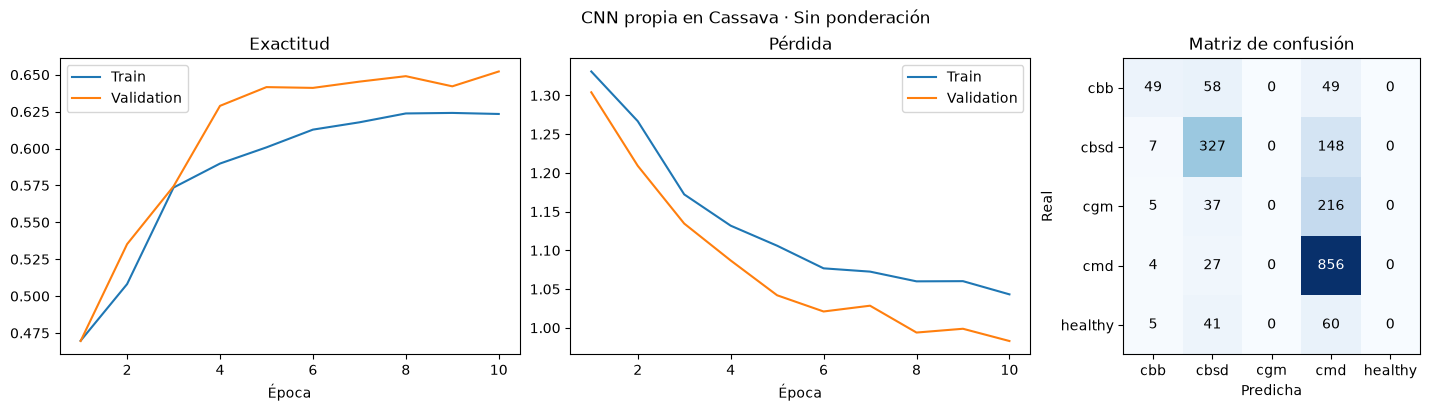


CNN propia · Con ponderación
Exactitud: 63.63%
F1 macro: 0.4529
cbb: 62/156 correctas · F1: 0.4921
cbsd: 249/482 correctas · F1: 0.6081
cgm: 21/258 correctas · F1: 0.1280
cmd: 852/887 correctas · F1: 0.7573
healthy: 18/106 correctas · F1: 0.2791


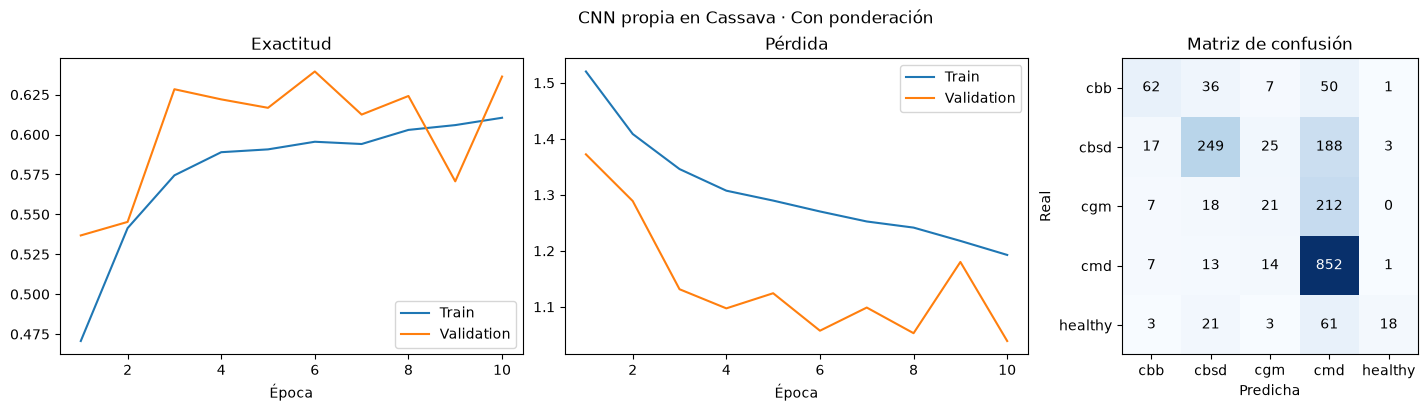

In [10]:
# Ubicar las dos corridas guardadas en la carpeta de Cassava.
actual = Path.cwd()
cassava = actual if actual.name == "cassava" else actual / "cassava"
resultados = cassava / "resultados" / "cnn_propia"

corridas = {
    "Sin ponderación": "corrida_01_sin_ponderacion",
    "Con ponderación": "corrida_02_ponderada",
}

for nombre, carpeta in corridas.items():
    ruta = resultados / carpeta
    with (ruta / "historial.csv").open(encoding="utf-8-sig", newline="") as archivo:
        historial = list(csv.DictReader(archivo))
    epocas = [int(fila["epoch"]) + 1 for fila in historial]

    # Evaluar el modelo que se guardó durante el entrenamiento en Colab.
    modelo = tf.keras.models.load_model(ruta / "mejor_modelo.keras", compile=False)
    matriz = np.zeros((len(clases), len(clases)), dtype=int)

    for imagenes, etiquetas in val_preparado:
        predichas = np.argmax(modelo(imagenes, training=False).numpy(), axis=1)
        np.add.at(matriz, (etiquetas.numpy(), predichas), 1)

    # Calcular el F1 por clase y el promedio de las cinco clases.
    aciertos = matriz.diagonal()
    reales = matriz.sum(axis=1)
    predichas = matriz.sum(axis=0)
    f1 = 2 * aciertos / np.maximum(reales + predichas, 1)

    print(f"\nCNN propia · {nombre}")
    print(f"Exactitud: {aciertos.sum() / matriz.sum():.2%}")
    print(f"F1 macro: {f1.mean():.4f}")
    for clase, correctas, total, f1_clase in zip(clases, aciertos, reales, f1):
        print(f"{clase}: {correctas}/{total} correctas · F1: {f1_clase:.4f}")

    # Mostrar las curvas y la matriz de confusión de esta corrida.
    fig, ejes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
    fig.suptitle(f"CNN propia en Cassava · {nombre}")

    for eje, metrica, titulo in zip(ejes[:2], ("accuracy", "loss"), ("Exactitud", "Pérdida")):
        eje.plot(epocas, [float(fila[metrica]) for fila in historial], label="Train")
        eje.plot(epocas, [float(fila[f"val_{metrica}"]) for fila in historial], label="Validation")
        eje.set(title=titulo, xlabel="Época")
        eje.legend()

    eje_matriz = ejes[2]
    eje_matriz.imshow(matriz, cmap="Blues")
    eje_matriz.set_xticks(range(len(clases)), labels=clases)
    eje_matriz.set_yticks(range(len(clases)), labels=clases)
    eje_matriz.set(title="Matriz de confusión", xlabel="Predicha", ylabel="Real")
    for fila, columna in np.ndindex(matriz.shape):
        valor = matriz[fila, columna]
        color = "white" if valor > matriz.max() / 2 else "black"
        eje_matriz.text(columna, fila, str(valor), ha="center", va="center", color=color)

    fig.savefig(ruta / "curvas_y_matriz_validacion.png", dpi=200)
    plt.show()
    plt.close(fig)

In [24]:
# TERCER ENSAYO: CNN propia ponderada con promedio y máximo global
# Ubicar Cassava desde la carpeta principal del proyecto o desde Cassava.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual
    if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)

if not (carpeta_cassava / "CNN_Propia.ipynb").is_file():
    raise FileNotFoundError("Abre la carpeta BeanCass AI en VS Code.")

# Crear una carpeta exclusiva para el historial y el modelo de este ensayo.
carpeta_resultados = carpeta_cassava / "resultados" / "cnn_propia"
carpeta_resultados.mkdir(parents=True, exist_ok=True)

carpeta_03 = Path(
    mkdtemp(prefix="corrida_03_promedio_maximo_", dir=carpeta_resultados)
)
ruta_modelo_03 = carpeta_03 / "mejor_modelo.keras"

# Calcular los mismos pesos por clase que en la segunda corrida.
conteos_train = np.asarray(conteos["Train"], dtype=float)
pesos = 1.0 / np.sqrt(conteos_train)
pesos /= np.average(pesos, weights=conteos_train)
pesos_clase_03 = {indice: float(peso) for indice, peso in enumerate(pesos)}

# Construir la CNN desde cero, con la misma semilla y los mismos bloques.
keras.utils.set_random_seed(42)
entrada = keras.Input(shape=(*IMG_SIZE, 3))
x = layers.Rescaling(1.0 / 255)(entrada)

for filtros in (32, 64, 128):
    x = layers.Conv2D(
        filtros, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D(2)(x)

# Cambio de este ensayo: combinar el promedio y el máximo de cada filtro.
promedio = layers.GlobalAveragePooling2D()(x)
maximo = layers.GlobalMaxPooling2D()(x)
x = layers.Concatenate()([promedio, maximo])
x = layers.Dropout(0.25)(x)
salida = layers.Dense(len(clases), activation="softmax")(x)

cnn_03 = keras.Model(
    entrada, salida, name="cnn_cassava_promedio_maximo"
)
cnn_03.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

# Preparar Train con la misma configuración del segundo ensayo.
train_corrida_03 = preparar_dataset(ds_train, entrenamiento=True)

for indice, clase in enumerate(clases):
    print(f"{clase}: {int(conteos_train[indice])} fotos · peso {pesos[indice]:.2f}")

print("\nGPU detectada:", tf.config.list_physical_devices("GPU"))
print("Carpeta de resultados:", carpeta_03.resolve())

inicio = perf_counter()

historial_cnn_03 = cnn_03.fit(
    train_corrida_03,
    validation_data=val_preparado,
    class_weight=pesos_clase_03,
    epochs=10,
    shuffle=False,
    callbacks=[
        keras.callbacks.CSVLogger(str(carpeta_03 / "historial.csv")),
        keras.callbacks.ModelCheckpoint(
            str(ruta_modelo_03),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=3,
            restore_best_weights=True,
        ),
        keras.callbacks.TerminateOnNaN(),
    ],
    verbose=1,
)

duracion = perf_counter() - inicio
metricas_03 = historial_cnn_03.history
mejor_indice = int(np.argmin(metricas_03["val_loss"]))

print(f"\nTiempo de entrenamiento: {duracion / 60:.2f} minutos")
print(f"Época guardada: {mejor_indice + 1}")
print(f"Exactitud de validación: {metricas_03['val_accuracy'][mejor_indice]:.2%}")
print(f"Pérdida de validación: {metricas_03['val_loss'][mejor_indice]:.4f}")
print("Archivos guardados en:", carpeta_03.resolve())

cbb: 466 fotos · peso 1.67
cbsd: 1443 fotos · peso 0.95
cgm: 773 fotos · peso 1.30
cmd: 2658 fotos · peso 0.70
healthy: 316 fotos · peso 2.03

GPU detectada: []
Carpeta de resultados: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia\corrida_03_promedio_maximo_3dtbedib
Epoch 1/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 54s 289ms/step - accuracy: 0.5083 - loss: 1.4604 - val_accuracy: 0.5193 - val_loss: 1.2875
Epoch 2/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 57s 318ms/step - accuracy: 0.5124 - loss: 1.3698 - val_accuracy: 0.5283 - val_loss: 1.2213
Epoch 3/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 52s 290ms/step - accuracy: 0.5357 - loss: 1.3127 - val_accuracy: 0.5738 - val_loss: 1.1523
Epoch 4/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 52s 289ms/step - accuracy: 0.5591 - loss: 1.2674 - val_accuracy: 0.6072 - val_loss: 1.0754
Epoch 5/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 53s 294ms/step - accuracy: 0.5624 - loss: 1.2411 - val_accuracy: 0.5357 - val_loss: 1.1884
Ep

Época guardada: 7
Exactitud en validación: 63.63%
F1 macro: 0.4126

Clase    Aciertos    Precisión   Recall       F1
cbb       79/156     50.32%    50.64%   0.5048
cbsd     288/482     70.94%    59.75%   0.6486
cgm        6/258     54.55%     2.33%   0.0446
cmd      822/887     63.43%    92.67%   0.7531
healthy    7/106     36.84%     6.60%   0.1120
cgm → cmd: 218
healthy → cmd: 58


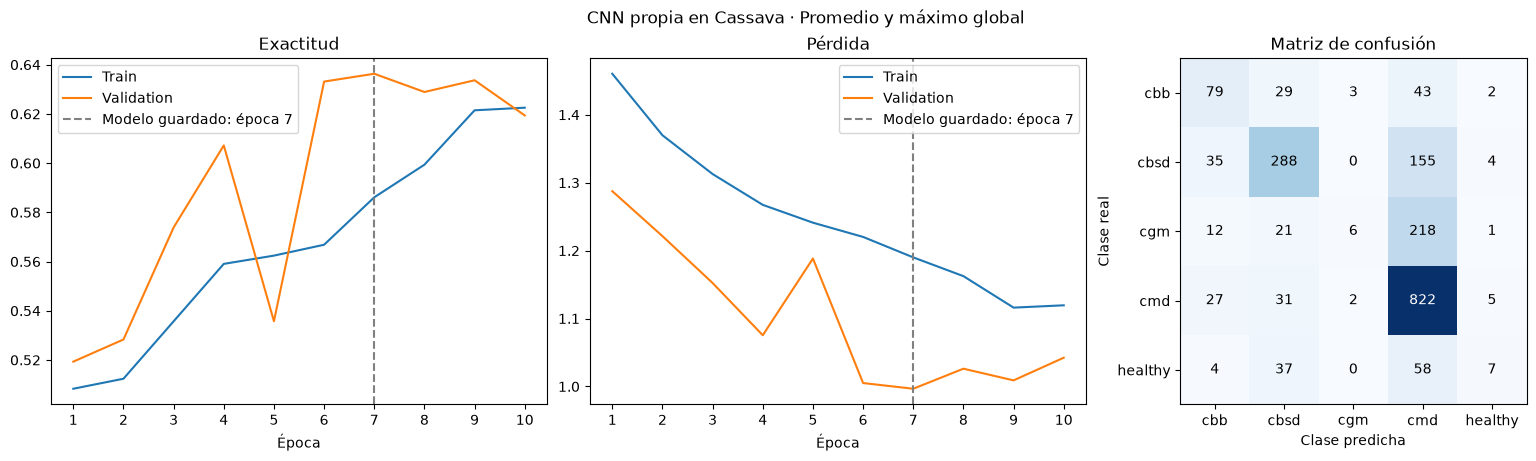


Figura guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia\corrida_03_promedio_maximo_3dtbedib\curvas_y_matriz_validacion.png


In [25]:
# Evaluar el modelo guardado del tercer ensayo en Validation.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)
carpeta_03 = (
    carpeta_cassava / "resultados" / "cnn_propia"
    / "corrida_03_promedio_maximo_3dtbedib"
)

with (carpeta_03 / "historial.csv").open(
    encoding="utf-8-sig", newline=""
) as archivo:
    registros = list(csv.DictReader(archivo))

epocas = [int(fila["epoch"]) + 1 for fila in registros]
mejor_fila = min(registros, key=lambda fila: float(fila["val_loss"]))
mejor_epoca = int(mejor_fila["epoch"]) + 1

modelo_03 = keras.models.load_model(
    str(carpeta_03 / "mejor_modelo.keras"), compile=False
)
nombres = list(clases)
matriz_03 = np.zeros((len(nombres), len(nombres)), dtype=int)

# Contar cada predicción en la fila real y la columna predicha.
for imagenes, etiquetas in val_preparado:
    predicciones = np.argmax(
        modelo_03(imagenes, training=False).numpy(), axis=1
    )
    np.add.at(matriz_03, (etiquetas.numpy(), predicciones), 1)

aciertos = matriz_03.diagonal()
reales = matriz_03.sum(axis=1)
predichas = matriz_03.sum(axis=0)
precision = aciertos / np.maximum(predichas, 1)
recall = aciertos / np.maximum(reales, 1)
f1 = 2 * aciertos / np.maximum(reales + predichas, 1)

print(f"Época guardada: {mejor_epoca}")
print(f"Exactitud en validación: {aciertos.sum() / reales.sum():.2%}")
print(f"F1 macro: {f1.mean():.4f}")

print("\nClase    Aciertos    Precisión   Recall       F1")
for i, clase in enumerate(nombres):
    print(
        f"{clase:<8} {aciertos[i]:>3}/{reales[i]:<5}"
        f" {precision[i]:>8.2%} {recall[i]:>9.2%} {f1[i]:>8.4f}"
    )

indice_cmd = nombres.index("cmd")
for clase in ("cgm", "healthy"):
    print(f"{clase} → cmd: {matriz_03[nombres.index(clase), indice_cmd]}")

# Graficar las curvas y señalar la época del modelo guardado.
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")
fig.suptitle("CNN propia en Cassava · Promedio y máximo global")

for eje, metrica, titulo in zip(
    ejes[:2], ("accuracy", "loss"), ("Exactitud", "Pérdida")
):
    eje.plot(epocas, [float(fila[metrica]) for fila in registros], label="Train")
    eje.plot(
        epocas, [float(fila[f"val_{metrica}"]) for fila in registros],
        label="Validation",
    )
    eje.axvline(
        mejor_epoca, color="gray", linestyle="--",
        label=f"Modelo guardado: época {mejor_epoca}",
    )
    eje.set(title=titulo, xlabel="Época", xticks=epocas)
    eje.legend()

# Mostrar la matriz de confusión con sus conteos.
eje_matriz = ejes[2]
eje_matriz.imshow(matriz_03, cmap="Blues")
eje_matriz.set_xticks(range(len(nombres)), labels=nombres)
eje_matriz.set_yticks(range(len(nombres)), labels=nombres)
eje_matriz.set(
    title="Matriz de confusión", xlabel="Clase predicha", ylabel="Clase real"
)

for fila, columna in np.ndindex(matriz_03.shape):
    valor = matriz_03[fila, columna]
    color = "white" if valor > matriz_03.max() / 2 else "black"
    eje_matriz.text(columna, fila, str(valor), ha="center", va="center", color=color)

ruta_figura = carpeta_03 / "curvas_y_matriz_validacion.png"
fig.savefig(ruta_figura, dpi=200)
plt.show()
plt.close(fig)

print("\nFigura guardada en:", ruta_figura.resolve())

In [26]:
# CUARTO ENSAYO: CNN propia con pesos ajustados para cgm y healthy
# Partir de la ponderación de la segunda corrida.
conteos_train = np.asarray(conteos["Train"], dtype=float)
pesos_base = 1.0 / np.sqrt(conteos_train)
nombres_clases = list(clases)

# Aumentar el peso relativo de las dos clases que más cuesta reconocer.
pesos_04 = pesos_base.copy()
pesos_04[nombres_clases.index("cgm")] *= 1.20
pesos_04[nombres_clases.index("healthy")] *= 1.15

# Mantener en 1 el peso promedio por imagen de entrenamiento.
pesos_04 /= np.average(pesos_04, weights=conteos_train)
pesos_clase_04 = {i: float(peso) for i, peso in enumerate(pesos_04)}

# Construir desde cero la misma arquitectura de la segunda corrida.
keras.utils.set_random_seed(42)

cnn_04 = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.25),
    layers.Dense(len(clases), activation="softmax"),
], name="cnn_cassava_pesos_ajustados")

cnn_04.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

# Crear una carpeta exclusiva para los archivos del cuarto ensayo.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)
if not (carpeta_cassava / "CNN_Propia.ipynb").is_file():
    raise FileNotFoundError("Abre la carpeta BeanCass AI en VS Code.")

carpeta_resultados = carpeta_cassava / "resultados" / "cnn_propia"
carpeta_resultados.mkdir(parents=True, exist_ok=True)
carpeta_04 = Path(mkdtemp(
    prefix="corrida_04_pesos_ajustados_", dir=carpeta_resultados
))
ruta_modelo_04 = carpeta_04 / "mejor_modelo.keras"

for clase, peso in zip(clases, pesos_04):
    print(f"{clase}: peso {peso:.2f}")
print("\nCarpeta de resultados:", carpeta_04.resolve())

# Mantener las mismas particiones y el mismo límite de épocas.
train_corrida_04 = preparar_dataset(ds_train, entrenamiento=True)
inicio = perf_counter()

historial_cnn_04 = cnn_04.fit(
    train_corrida_04,
    validation_data=val_preparado,
    class_weight=pesos_clase_04,
    epochs=10,
    shuffle=False,
    callbacks=[
        keras.callbacks.CSVLogger(str(carpeta_04 / "historial.csv")),
        keras.callbacks.ModelCheckpoint(
            str(ruta_modelo_04),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=3,
            restore_best_weights=True,
        ),
        keras.callbacks.TerminateOnNaN(),
    ],
    verbose=1,
)

metricas_04 = historial_cnn_04.history
mejor_indice = int(np.argmin(metricas_04["val_loss"]))

print(f"\nTiempo de entrenamiento: {(perf_counter() - inicio) / 60:.2f} minutos")
print(f"Época guardada: {mejor_indice + 1}")
print(f"Exactitud de validación: {metricas_04['val_accuracy'][mejor_indice]:.2%}")
print(f"Pérdida de validación: {metricas_04['val_loss'][mejor_indice]:.4f}")
print("Archivos guardados en:", carpeta_04.resolve())

cbb: peso 1.59
cbsd: peso 0.90
cgm: peso 1.48
cmd: peso 0.67
healthy: peso 2.22

Carpeta de resultados: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia\corrida_04_pesos_ajustados_c2ylnp2l
Epoch 1/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 52s 279ms/step - accuracy: 0.4694 - loss: 1.5321 - val_accuracy: 0.5363 - val_loss: 1.3789
Epoch 2/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 50s 278ms/step - accuracy: 0.5279 - loss: 1.4334 - val_accuracy: 0.5352 - val_loss: 1.3120
Epoch 3/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 49s 275ms/step - accuracy: 0.5704 - loss: 1.3703 - val_accuracy: 0.6252 - val_loss: 1.1450
Epoch 4/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 50s 278ms/step - accuracy: 0.5849 - loss: 1.3249 - val_accuracy: 0.6363 - val_loss: 1.1005
Epoch 5/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 49s 276ms/step - accuracy: 0.5835 - loss: 1.3061 - val_accuracy: 0.6199 - val_loss: 1.1398
Epoch 6/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 50s 277ms/step - accuracy: 0.5842 - loss: 

Época guardada: 6
Exactitud en validación: 64.32%
F1 macro: 0.4059

Clase    Aciertos    Precisión   Recall       F1
cbb       84/156     56.38%    53.85%   0.5508
cbsd     290/482     67.44%    60.17%   0.6360
cgm       11/258     33.33%     4.26%   0.0756
cmd      830/887     65.00%    93.57%   0.7671
healthy    0/106      0.00%     0.00%   0.0000
cgm → cmd: 207
healthy → cmd: 56


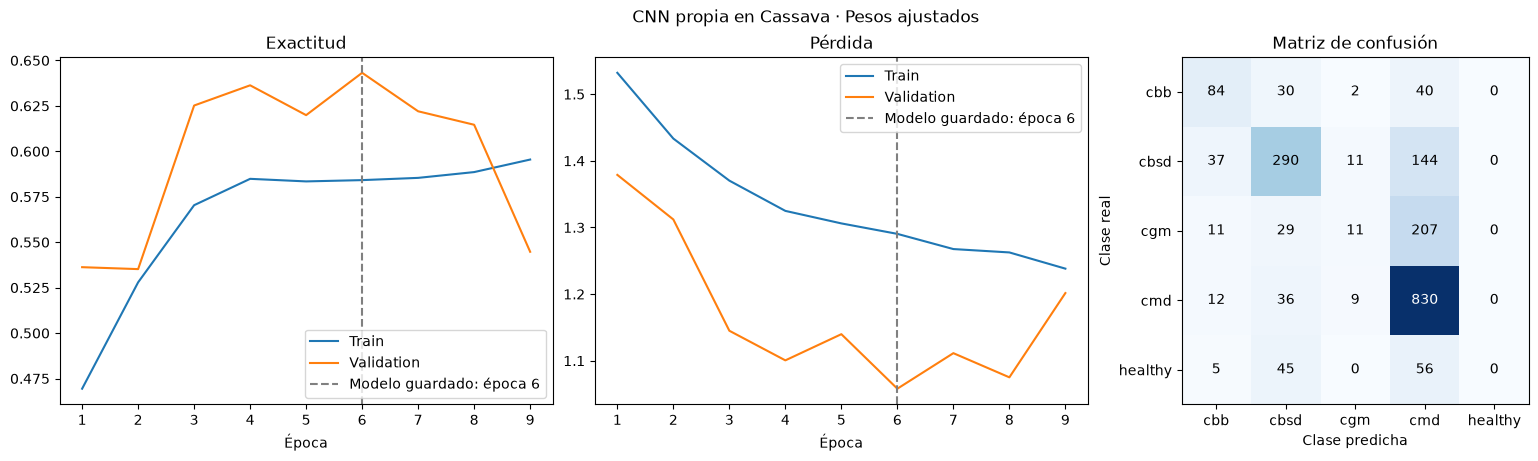


Figura guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia\corrida_04_pesos_ajustados_c2ylnp2l\curvas_y_matriz_validacion.png


In [27]:
# Evaluar el modelo guardado de la cuarta corrida en Validation.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)
carpeta_04 = (
    carpeta_cassava / "resultados" / "cnn_propia"
    / "corrida_04_pesos_ajustados_c2ylnp2l"
)

with (carpeta_04 / "historial.csv").open(
    encoding="utf-8-sig", newline=""
) as archivo:
    historial = list(csv.DictReader(archivo))

epocas = [int(fila["epoch"]) + 1 for fila in historial]
mejor_fila = min(historial, key=lambda fila: float(fila["val_loss"]))
mejor_epoca = int(mejor_fila["epoch"]) + 1

modelo_04 = keras.models.load_model(
    str(carpeta_04 / "mejor_modelo.keras"), compile=False
)
nombres = list(clases)
matriz_04 = np.zeros((len(nombres), len(nombres)), dtype=int)

for imagenes, etiquetas in val_preparado:
    predicciones = np.argmax(
        modelo_04(imagenes, training=False).numpy(), axis=1
    )
    np.add.at(matriz_04, (etiquetas.numpy(), predicciones), 1)

# Calcular las métricas globales y por clase.
aciertos = matriz_04.diagonal()
reales = matriz_04.sum(axis=1)
predichas = matriz_04.sum(axis=0)
precision = aciertos / np.maximum(predichas, 1)
recall = aciertos / np.maximum(reales, 1)
f1 = 2 * aciertos / np.maximum(reales + predichas, 1)

print(f"Época guardada: {mejor_epoca}")
print(f"Exactitud en validación: {aciertos.sum() / reales.sum():.2%}")
print(f"F1 macro: {f1.mean():.4f}")

print("\nClase    Aciertos    Precisión   Recall       F1")
for i, clase in enumerate(nombres):
    print(
        f"{clase:<8} {aciertos[i]:>3}/{reales[i]:<5}"
        f" {precision[i]:>8.2%} {recall[i]:>9.2%} {f1[i]:>8.4f}"
    )

indice_cmd = nombres.index("cmd")
for clase in ("cgm", "healthy"):
    print(f"{clase} → cmd: {matriz_04[nombres.index(clase), indice_cmd]}")

# Graficar las curvas y marcar la época guardada.
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")
fig.suptitle("CNN propia en Cassava · Pesos ajustados")

for eje, metrica, titulo in zip(
    ejes[:2], ("accuracy", "loss"), ("Exactitud", "Pérdida")
):
    eje.plot(epocas, [float(fila[metrica]) for fila in historial], label="Train")
    eje.plot(
        epocas, [float(fila[f"val_{metrica}"]) for fila in historial],
        label="Validation",
    )
    eje.axvline(
        mejor_epoca, color="gray", linestyle="--",
        label=f"Modelo guardado: época {mejor_epoca}",
    )
    eje.set(title=titulo, xlabel="Época", xticks=epocas)
    eje.legend()

# Mostrar la matriz con las clases reales en las filas.
eje_matriz = ejes[2]
eje_matriz.imshow(matriz_04, cmap="Blues")
eje_matriz.set_xticks(range(len(nombres)), labels=nombres)
eje_matriz.set_yticks(range(len(nombres)), labels=nombres)
eje_matriz.set(
    title="Matriz de confusión", xlabel="Clase predicha", ylabel="Clase real"
)

for fila, columna in np.ndindex(matriz_04.shape):
    valor = matriz_04[fila, columna]
    color = "white" if valor > matriz_04.max() / 2 else "black"
    eje_matriz.text(columna, fila, str(valor), ha="center", va="center", color=color)

ruta_figura = carpeta_04 / "curvas_y_matriz_validacion.png"
fig.savefig(ruta_figura, dpi=200)
plt.show()
plt.close(fig)
print("\nFigura guardada en:", ruta_figura.resolve())

In [28]:
# QUINTO ENSAYO: CNN propia ponderada con normalización por lotes

# Ubicar Cassava desde la raíz del proyecto o desde la carpeta cassava.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)

if not (carpeta_cassava / "CNN_Propia.ipynb").is_file():
    raise FileNotFoundError("Abre la carpeta BeanCass AI en VS Code.")

# Recuperar la ponderación de la segunda corrida.
conteos_train = np.asarray(conteos["Train"], dtype=float)
pesos_05 = 1.0 / np.sqrt(conteos_train)
pesos_05 /= np.average(pesos_05, weights=conteos_train)
pesos_clase_05 = {i: float(peso) for i, peso in enumerate(pesos_05)}

# Construir un modelo nuevo con la misma semilla.
keras.utils.set_random_seed(42)

entrada = keras.Input(shape=(*IMG_SIZE, 3))
x = layers.Rescaling(1.0 / 255)(entrada)

# Cada bloque normaliza las señales de la convolución antes de ReLU.
for filtros in (32, 64, 128):
    x = layers.Conv2D(filtros, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)

# Mantener el promedio global y la capa final de la segunda corrida.
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
salida = layers.Dense(len(clases), activation="softmax")(x)

cnn_05 = keras.Model(entrada, salida, name="cnn_cassava_batchnorm")
cnn_05.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

# Crear una carpeta exclusiva para el historial y el mejor modelo.
carpeta_resultados = carpeta_cassava / "resultados" / "cnn_propia"
carpeta_resultados.mkdir(parents=True, exist_ok=True)
carpeta_05 = Path(mkdtemp(prefix="corrida_05_batchnorm_", dir=carpeta_resultados))
ruta_modelo_05 = carpeta_05 / "mejor_modelo.keras"

for clase, peso in zip(clases, pesos_05):
    print(f"{clase}: peso {peso:.2f}")
print("\nCarpeta de resultados:", carpeta_05.resolve())

# Entrenar desde cero y guardar la época con menor pérdida de validación.
train_corrida_05 = preparar_dataset(ds_train, entrenamiento=True)
inicio = perf_counter()

historial_cnn_05 = cnn_05.fit(
    train_corrida_05,
    validation_data=val_preparado,
    class_weight=pesos_clase_05,
    epochs=10,
    shuffle=False,
    callbacks=[
        keras.callbacks.CSVLogger(str(carpeta_05 / "historial.csv")),
        keras.callbacks.ModelCheckpoint(
            str(ruta_modelo_05),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=3,
            restore_best_weights=True,
        ),
        keras.callbacks.TerminateOnNaN(),
    ],
    verbose=1,
)

metricas_05 = historial_cnn_05.history
mejor_indice = int(np.argmin(metricas_05["val_loss"]))

print(f"\nTiempo de entrenamiento: {(perf_counter() - inicio) / 60:.2f} minutos")
print(f"Época guardada: {mejor_indice + 1}")
print(f"Exactitud de validación: {metricas_05['val_accuracy'][mejor_indice]:.2%}")
print(f"Pérdida de validación: {metricas_05['val_loss'][mejor_indice]:.4f}")
print("Archivos guardados en:", carpeta_05.resolve())

cbb: peso 1.67
cbsd: peso 0.95
cgm: peso 1.30
cmd: peso 0.70
healthy: peso 2.03

Carpeta de resultados: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia\corrida_05_batchnorm_xfxbnz4y
Epoch 1/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 116s 641ms/step - accuracy: 0.4936 - loss: 1.4164 - val_accuracy: 0.0879 - val_loss: 3.7863
Epoch 2/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 117s 657ms/step - accuracy: 0.5545 - loss: 1.2890 - val_accuracy: 0.0995 - val_loss: 3.6144
Epoch 3/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 114s 639ms/step - accuracy: 0.5755 - loss: 1.2433 - val_accuracy: 0.1583 - val_loss: 1.7374
Epoch 4/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 114s 638ms/step - accuracy: 0.5972 - loss: 1.2057 - val_accuracy: 0.5331 - val_loss: 1.4552
Epoch 5/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 113s 638ms/step - accuracy: 0.6025 - loss: 1.1776 - val_accuracy: 0.2155 - val_loss: 1.7812
Epoch 6/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 114s 643ms/step - accuracy: 0.6193 - loss: 

Época guardada: 9
Exactitud en validación: 62.04%
F1 macro: 0.4425

Clase    Aciertos    Precisión   Recall       F1
cbb        42/156      72.41%    26.92%   0.3925
cbsd      193/482      76.59%    40.04%   0.5259
cgm        21/258      47.73%     8.14%   0.1391
cmd       881/887      59.97%    99.32%   0.7479
healthy    35/106      53.03%    33.02%   0.4070

cgm → cmd: 221
healthy → cmd: 51

Figura guardada en: C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\cnn_propia\corrida_05_batchnorm_xfxbnz4y\curvas_y_matriz_validacion.png


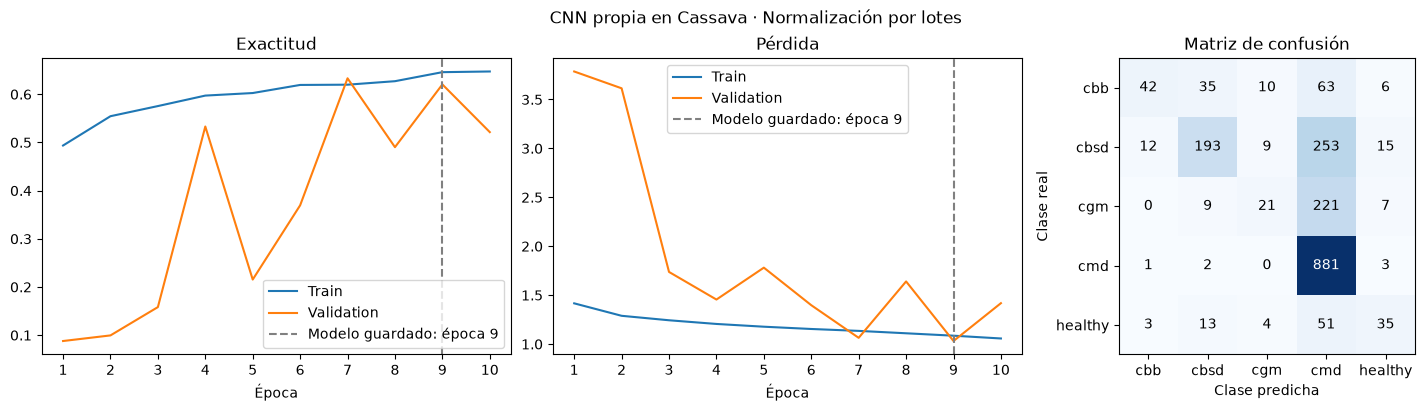

In [30]:
# Quinta corrida: reporte, curvas y matriz de confusión en validación.
actual = Path.cwd()
cassava = actual if actual.name == "cassava" else actual / "cassava"
carpeta_05 = (
    cassava / "resultados" / "cnn_propia" / "corrida_05_batchnorm_xfxbnz4y"
)

# Leer el historial e identificar la época con menor pérdida de validación.
with (carpeta_05 / "historial.csv").open(encoding="utf-8-sig", newline="") as archivo:
    historial_05 = list(csv.DictReader(archivo))

epocas_05 = [int(fila["epoch"]) + 1 for fila in historial_05]
mejor_fila_05 = min(historial_05, key=lambda fila: float(fila["val_loss"]))
epoca_guardada_05 = int(mejor_fila_05["epoch"]) + 1

# Cargar el modelo guardado y contar sus predicciones en Validation.
modelo_05 = keras.models.load_model(
    carpeta_05 / "mejor_modelo.keras", compile=False
)
matriz_05 = np.zeros((len(clases), len(clases)), dtype=int)

for imagenes, etiquetas in val_preparado:
    probabilidades = modelo_05(imagenes, training=False).numpy()
    predicciones = np.argmax(probabilidades, axis=1)
    np.add.at(matriz_05, (etiquetas.numpy(), predicciones), 1)

# Calcular la exactitud general y las métricas de cada clase.
aciertos_05 = matriz_05.diagonal()
reales_05 = matriz_05.sum(axis=1)
predichas_05 = matriz_05.sum(axis=0)

exactitud_05 = aciertos_05.sum() / matriz_05.sum()
precision_05 = aciertos_05 / np.maximum(predichas_05, 1)
recall_05 = aciertos_05 / np.maximum(reales_05, 1)
f1_05 = 2 * aciertos_05 / np.maximum(reales_05 + predichas_05, 1)

print(f"Época guardada: {epoca_guardada_05}")
print(f"Exactitud en validación: {exactitud_05:.2%}")
print(f"F1 macro: {f1_05.mean():.4f}")

print("\nClase    Aciertos    Precisión   Recall       F1")
for i, clase in enumerate(clases):
    aciertos_clase = f"{aciertos_05[i]}/{reales_05[i]}"
    print(
        f"{clase:<8} {aciertos_clase:>8}"
        f" {precision_05[i]:>11.2%} {recall_05[i]:>9.2%} {f1_05[i]:>8.4f}"
    )

# Contar las fotos de ácaro y las hojas sanas clasificadas como mosaico.
nombres_05 = list(clases)
indice_cgm_05 = nombres_05.index("cgm")
indice_cmd_05 = nombres_05.index("cmd")
indice_healthy_05 = nombres_05.index("healthy")

print(f"\ncgm → cmd: {matriz_05[indice_cgm_05, indice_cmd_05]}")
print(f"healthy → cmd: {matriz_05[indice_healthy_05, indice_cmd_05]}")

# Graficar la exactitud y la pérdida, marcando la época guardada.
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
fig.suptitle("CNN propia en Cassava · Normalización por lotes")

for eje, metrica, titulo in zip(
    ejes[:2], ("accuracy", "loss"), ("Exactitud", "Pérdida")
):
    valores_train = [float(fila[metrica]) for fila in historial_05]
    valores_val = [float(fila[f"val_{metrica}"]) for fila in historial_05]

    eje.plot(epocas_05, valores_train, label="Train")
    eje.plot(epocas_05, valores_val, label="Validation")
    eje.axvline(
        epoca_guardada_05,
        color="gray",
        linestyle="--",
        label=f"Modelo guardado: época {epoca_guardada_05}",
    )
    eje.set(title=titulo, xlabel="Época", xticks=epocas_05)
    eje.legend()

# Mostrar las clases reales en las filas y las predichas en las columnas.
eje_matriz = ejes[2]
eje_matriz.imshow(matriz_05, cmap="Blues")
eje_matriz.set_xticks(range(len(nombres_05)), labels=nombres_05)
eje_matriz.set_yticks(range(len(nombres_05)), labels=nombres_05)
eje_matriz.set(
    title="Matriz de confusión",
    xlabel="Clase predicha",
    ylabel="Clase real",
)

umbral_color_05 = matriz_05.max() / 2
for fila, columna in np.ndindex(matriz_05.shape):
    valor = matriz_05[fila, columna]
    color = "white" if valor > umbral_color_05 else "black"
    eje_matriz.text(
        columna, fila, str(valor), ha="center", va="center", color=color
    )

# Guardar y mostrar la figura de la quinta corrida.
ruta_figura_05 = carpeta_05 / "curvas_y_matriz_validacion.png"
fig.savefig(ruta_figura_05, dpi=200)
print(f"\nFigura guardada en: {ruta_figura_05.resolve()}")
plt.show()
plt.close(fig)